# Field Shift · Projections and scenario simulator (model level)

Uses the **standard tested models** (`artifacts/final_model/`, read-only) with `fs_ml.project`: an analog ensemble
(each past year's weather for the coming months) run month by month from the observed state of each 2 km cell.
Rules written and committed before this notebook ran: [`docs/ML_PROJECTIONS.md` §3](../../docs/ML_PROJECTIONS.md).
Writes only to `artifacts/projections/`. No web, no backend.

## 1. Setup

In [1]:
import sys, json, math, time, platform, warnings
warnings.filterwarnings("ignore", message="All-NaN slice")
from pathlib import Path
import numpy as np, pandas as pd, xgboost as xgb
import matplotlib.pyplot as plt
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from fs_ml import data as D, features as F, evaluate as E, enso as N, project as P
from fs_ml.predict import load

SEED, N_BOOT, NOMINAL = 42, 1000, 0.90
pd.set_option("display.width", 170, "display.max_columns", 30)
ART = ML_DIR / "artifacts" / "projections"; ART.mkdir(parents=True, exist_ok=True)
POOL_HINDCAST = list(range(1998, 2018))   # analog months never after Dec 2017 (no scored year inside a member)
SM, ND = load("sm_root_monthly"), load("ndvi_quarterly")
SHA = {n: D.sha256(ML_DIR / "artifacts" / "final_model" / n / "model.ubj") for n in ["sm_root_monthly", "ndvi_quarterly"]}
assert SHA["sm_root_monthly"] == SM["card"]["sha256"] and SHA["ndvi_quarterly"] == ND["card"]["sha256"]
print({k: v[:16] for k, v in SHA.items()}, "| xgboost", xgb.__version__)

{'sm_root_monthly': 'a4bbaf1397c43e2c', 'ndvi_quarterly': 'effe57ea2506d509'} | xgboost 3.4.1


## 2. One table 1998–2025 (same `fs_ml` code as every phase) and the cube

In [2]:
def build(load_years, suffix, keep):
    monthly, _ = D.load_gee_monthly(load_years); veg, _ = D.load_gee_quarterly(load_years)
    pw = {p: D.load_power(f"power_{p}{suffix}", load_years)[0] for p in ["t2m", "rh2m", "ws2m", "allsky"]}
    merra = pw["t2m"].merge(pw["rh2m"], on=["power_lat", "power_lon", "date"]).merge(pw["ws2m"], on=["power_lat", "power_lon", "date"])
    gaez = {k: D.load_gaez(k)[0] for k in F.GAEZ_FEATURES}
    cells = F.static_cells(D.cells_from_ids(monthly.cell_id), gaez, merra[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True),
                           pw["allsky"][["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True))
    mp = F.build_monthly_panel(monthly, cells, merra, pw["allsky"]); qp = F.build_quarterly_panel(mp, veg)
    extra = pd.DataFrame({"cell_id": cells.cell_id.to_numpy(), "block": np.asarray(E.spatial_blocks(cells.lat, cells.lon)),
                          "province": np.asarray(D.provinces_of(cells))})
    mp, qp = mp.merge(extra, on="cell_id"), qp.merge(extra, on="cell_id")
    return mp[mp.year.between(*keep)], qp[qp.year.between(*keep)]

parts = [build((1998, 2017), "", (1998, 2017)), build((2017, 2022), "_2018_2022", (2018, 2022)), build((2022, 2025), "_2023_2025", (2023, 2025))]
MP = pd.concat([p[0] for p in parts], ignore_index=True); QP = pd.concat([p[1] for p in parts], ignore_index=True)
assert not MP.duplicated(["cell_id", "date"]).any()
CUBE = P.build_cube(MP, QP)
print("cube:", len(CUBE.cells), "cells,", CUBE.dates[0].date(), "->", CUBE.dates[-1].date(), "|", CUBE.quarters[0], "->", CUBE.quarters[-1])
VALID = ~np.isnan(CUBE.v["sm_root_m3m3"]).all(axis=1)
print("cells with soil water data:", int(VALID.sum()), "| without (coastal, no ERA5-Land):", int((~VALID).sum()))

cube: 3149 cells, 1998-01-01 -> 2025-12-01 | 1998Q1 -> 2025Q4
cells with soil water data: 3126 | without (coastal, no ERA5-Land): 23


### 2.1 Consistency check: with the real weather, lead 1 must equal the tested model's own prediction

In [3]:
start = pd.Timestamp("2019-01-01")
w = P.analog_weather(CUBE, start, 1, [2019])            # the real weather of Feb 2019
run = P.project_sm(SM, CUBE, start, 1, None, weather=w)
rows = MP[MP.date == "2019-02-01"].set_index("cell_id").reindex(CUBE.cells.cell_id)
direct = SM["model"].predict(rows[SM["features"]])
print("max |projection - direct prediction|:", float(np.nanmax(np.abs(run["members"][0, :, 0] - direct))))

max |projection - direct prediction|: 0.0


## 3. Hindcasts: soil water, leads 1–12 months

In [4]:
YEARS = CUBE.dates.year.to_numpy()
with np.errstate(all="ignore"):   # the 23 coastal cells without ERA5-Land stay NaN and are never scored
    CLIM_SM = {m: np.nanmean(CUBE.v["sm_root_m3m3"][:, (CUBE.dates.month == m) & (YEARS <= 2017)], axis=1) for m in range(1, 13)}

def hindcast_sm(starts, last_target, max_lead=12):
    out = []
    for s in starts:
        h = min(max_lead, (last_target.year - s.year) * 12 + last_target.month - s.month)
        if h < 1: continue
        run = P.project_sm(SM, CUBE, s, h, POOL_HINDCAST, until="2017-12-01")
        lo, med, hi = np.quantile(run["members"], [0.05, 0.5, 0.95], axis=0)
        i0 = CUBE.t(s); pers = CUBE.v["sm_root_m3m3"][:, i0]
        for k, d in enumerate(run["dates"]):
            y = CUBE.v["sm_root_m3m3"][:, CUBE.t(d)]
            ok = VALID & ~np.isnan(y)
            out.append(pd.DataFrame({"start": s, "date": d, "lead": k + 1, "cell_id": CUBE.cells.cell_id[ok], "block": CUBE.cells.block[ok],
                                     "y": y[ok], "median": med[ok, k], "lo": lo[ok, k], "hi": hi[ok, k],
                                     "climatology": CLIM_SM[d.month][ok], "persistence": pers[ok]}))
    return pd.concat(out, ignore_index=True)

t0 = time.time()
H_SM_VAL = hindcast_sm(pd.date_range("2017-12-01", "2022-11-01", freq="MS"), pd.Timestamp("2022-12-01"))
H_SM_TEST = hindcast_sm(pd.date_range("2022-12-01", "2025-11-01", freq="MS"), pd.Timestamp("2025-12-01"))
print(len(H_SM_VAL), len(H_SM_TEST), "rows |", round(time.time() - t0), "s")

/tmp/ipykernel_240005/2852987246.py:3: RuntimeWarning: Mean of empty slice
  CLIM_SM = {m: np.nanmean(CUBE.v["sm_root_m3m3"][:, (CUBE.dates.month == m) & (YEARS <= 2017)], axis=1) for m in range(1, 13)}
/tmp/ipykernel_240005/2852987246.py:3: RuntimeWarning: Mean of empty slice
  CLIM_SM = {m: np.nanmean(CUBE.v["sm_root_m3m3"][:, (CUBE.dates.month == m) & (YEARS <= 2017)], axis=1) for m in range(1, 13)}
/tmp/ipykernel_240005/2852987246.py:3: RuntimeWarning: Mean of empty slice
  CLIM_SM = {m: np.nanmean(CUBE.v["sm_root_m3m3"][:, (CUBE.dates.month == m) & (YEARS <= 2017)], axis=1) for m in range(1, 13)}
/tmp/ipykernel_240005/2852987246.py:3: RuntimeWarning: Mean of empty slice
  CLIM_SM = {m: np.nanmean(CUBE.v["sm_root_m3m3"][:, (CUBE.dates.month == m) & (YEARS <= 2017)], axis=1) for m in range(1, 13)}
/tmp/ipykernel_240005/2852987246.py:3: RuntimeWarning: Mean of empty slice
  CLIM_SM = {m: np.nanmean(CUBE.v["sm_root_m3m3"][:, (CUBE.dates.month == m) & (YEARS <= 2017)], axis=1) for m in

2044404 1144116 rows | 82 s


## 4. Hindcasts: NDVI, leads 1–4 quarters

In [5]:
QY = np.array([q.year for q in CUBE.quarters]); QQ = np.array([q.quarter for q in CUBE.quarters])
# cell mean per quarter 1998-2017; a cell with no NDVI in that quarter gets the regional mean (same fallback as Phases 2-3)
with np.errstate(all="ignore"):
    CLIM_ND = {q: np.nanmean(CUBE.ndvi[:, (QQ == q) & (QY <= 2017)], axis=1) for q in range(1, 5)}
CLIM_ND = {q: np.where(np.isnan(v), np.nanmean(v), v) for q, v in CLIM_ND.items()}

def hindcast_nd(starts, last_q, max_lead=4):
    out = []
    for s in starts:
        q0 = pd.Period(s, freq="Q"); h = min(max_lead, (last_q - q0).n)
        if h < 1: continue
        sm = P.project_sm(SM, CUBE, s, 3 * h, POOL_HINDCAST, until="2017-12-01"); run = P.project_ndvi(ND, CUBE, sm)
        lo, med, hi = np.quantile(run["members"], [0.05, 0.5, 0.95], axis=0)
        qi = CUBE.quarters.get_loc(q0); obs0 = CUBE.ndvi[:, qi]
        for k, q in enumerate(run["quarters"]):
            y = CUBE.ndvi[:, CUBE.quarters.get_loc(q)]; ok = ~np.isnan(y)
            pers = np.where(np.isnan(obs0), CLIM_ND[q.quarter], obs0)
            out.append(pd.DataFrame({"start": s, "quarter": str(q), "lead": k + 1, "cell_id": CUBE.cells.cell_id[ok], "block": CUBE.cells.block[ok],
                                     "y": y[ok], "median": med[ok, k], "lo": lo[ok, k], "hi": hi[ok, k],
                                     "climatology": CLIM_ND[q.quarter][ok], "persistence": pers[ok]}))
    return pd.concat(out, ignore_index=True)

qs = lambda a, b: [p.to_timestamp(how="end").normalize().replace(day=1) for p in pd.period_range(a, b, freq="Q")]
H_ND_VAL = hindcast_nd(qs("2017Q4", "2022Q3"), pd.Period("2022Q4"))
H_ND_TEST = hindcast_nd(qs("2022Q4", "2025Q3"), pd.Period("2025Q4"))
print(len(H_ND_VAL), len(H_ND_TEST), "rows")

/tmp/ipykernel_240005/3458030116.py:4: RuntimeWarning: Mean of empty slice
  CLIM_ND = {q: np.nanmean(CUBE.ndvi[:, (QQ == q) & (QY <= 2017)], axis=1) for q in range(1, 5)}


187017 105295 rows


## 5. Skill per lead (95 % CI) and the useful lead — decided on Validation

In [6]:
def skill_by_lead(H):
    rows = []
    for L, g in H.groupby("lead"):
        t = E.block_bootstrap(g.y.to_numpy(), {"projection": g["median"].to_numpy(), "climatology": g.climatology.to_numpy(),
                              "persistence": g.persistence.to_numpy()}, g.block.to_numpy(), reference="projection", n_boot=N_BOOT, seed=SEED).set_index(["model", "metric"])
        r = {"lead": L, "n": len(g), "RMSE": t.loc[("projection", "RMSE"), "value"], "RMSE_climatology": t.loc[("climatology", "RMSE"), "value"],
             "RMSE_persistence": t.loc[("persistence", "RMSE"), "value"], "bias": t.loc[("projection", "bias"), "value"]}
        best = "climatology" if r["RMSE_climatology"] < r["RMSE_persistence"] else "persistence"
        sk = t.loc[("projection", f"skill vs {best}")]
        rows.append(r | {"best_rule": best, "skill": sk.value, "skill_ci_low": sk.ci_low, "skill_ci_high": sk.ci_high})
    return pd.DataFrame(rows)

def useful_lead(tab):
    L = 0
    for _, r in tab.sort_values("lead").iterrows():
        if r.skill_ci_low > 0: L = int(r.lead)
        else: break
    return L

SK = {("sm", "validation"): skill_by_lead(H_SM_VAL), ("sm", "2023-2025"): skill_by_lead(H_SM_TEST),
      ("ndvi", "validation"): skill_by_lead(H_ND_VAL), ("ndvi", "2023-2025"): skill_by_lead(H_ND_TEST)}
USEFUL = {"sm": useful_lead(SK[("sm", "validation")]), "ndvi": useful_lead(SK[("ndvi", "validation")])}
for k, t in SK.items(): print("\n===", k); display(t.round(4))
print("USEFUL LEAD (decided on Validation):", USEFUL, "| for reference, on 2023-2025:", {v: useful_lead(SK[(v, "2023-2025")]) for v in ["sm", "ndvi"]})


=== ('sm', 'validation')


,lead,n,RMSE,RMSE_climatology,RMSE_persistence,bias,best_rule,skill,skill_ci_low,skill_ci_high
0,1,187560,0.0159,0.0317,0.0260,0.0005,persistence,0.3904,0.3429,0.4321
1,2,184434,0.0262,0.0318,0.0439,0.0016,climatology,0.1768,0.1368,0.2274
2,3,181308,0.0293,0.0319,0.0562,0.0018,climatology,0.0822,0.0460,0.1302
3,4,178182,0.0294,0.0312,0.0658,0.0015,climatology,0.0581,0.0217,0.1062
4,5,175056,0.0291,0.0306,0.0721,0.0013,climatology,0.0504,0.0133,0.0974
5,6,171930,0.0292,0.0304,0.0750,0.0013,climatology,0.0414,0.0048,0.0890
6,7,168804,0.0294,0.0304,0.0737,0.0017,climatology,0.0324,-0.0055,0.0803
7,8,165678,0.0297,0.0305,0.0684,0.0019,climatology,0.0253,-0.0125,0.0733
8,9,162552,0.0300,0.0307,0.0594,0.0023,climatology,0.0218,-0.0156,0.0698
9,10,159426,0.0303,0.0309,0.0487,0.0026,climatology,0.0202,-0.0159,0.0687



=== ('sm', '2023-2025')


,lead,n,RMSE,RMSE_climatology,RMSE_persistence,bias,best_rule,skill,skill_ci_low,skill_ci_high
0,1,112536,0.0239,0.0376,0.0367,-0.0034,persistence,0.3480,0.3137,0.3840
1,2,109410,0.0344,0.0380,0.0619,-0.0069,climatology,0.0937,0.0696,0.1190
2,3,106284,0.0377,0.0381,0.0783,-0.0086,climatology,0.0098,-0.0092,0.0346
3,4,103158,0.0393,0.0379,0.0881,-0.0089,climatology,-0.0360,-0.0572,-0.0078
4,5,100032,0.0370,0.0347,0.0914,-0.0077,climatology,-0.0659,-0.0899,-0.0331
5,6,96906,0.0361,0.0332,0.0932,-0.0073,climatology,-0.0874,-0.1158,-0.0522
6,7,93780,0.0360,0.0326,0.0922,-0.0072,climatology,-0.1018,-0.1330,-0.0652
7,8,90654,0.0362,0.0326,0.0871,-0.0075,climatology,-0.1103,-0.1416,-0.0729
8,9,87528,0.0365,0.0327,0.0770,-0.0078,climatology,-0.1161,-0.1493,-0.0781
9,10,84402,0.0372,0.0331,0.0660,-0.0082,climatology,-0.1247,-0.1605,-0.0847



=== ('ndvi', 'validation')


,lead,n,RMSE,RMSE_climatology,RMSE_persistence,bias,best_rule,skill,skill_ci_low,skill_ci_high
0,1,50477,0.1039,0.1256,0.1564,-0.0022,climatology,0.1732,0.0933,0.2507
1,2,48081,0.1116,0.1257,0.1821,0.0022,climatology,0.1123,0.0264,0.1894
2,3,45504,0.1119,0.1259,0.1650,0.0033,climatology,0.1112,0.0314,0.1794
3,4,42955,0.1130,0.1271,0.1260,0.0021,persistence,0.1031,0.0739,0.1281



=== ('ndvi', '2023-2025')


,lead,n,RMSE,RMSE_climatology,RMSE_persistence,bias,best_rule,skill,skill_ci_low,skill_ci_high
0,1,30056,0.1307,0.1605,0.1840,-0.0329,climatology,0.1857,0.1117,0.2566
1,2,27648,0.1437,0.1628,0.2247,-0.0387,climatology,0.1173,0.0375,0.1992
2,3,25084,0.1310,0.1508,0.1861,-0.0262,climatology,0.1318,0.0459,0.2125
3,4,22507,0.1292,0.1472,0.1583,-0.0199,climatology,0.1223,0.0301,0.2085


USEFUL LEAD (decided on Validation): {'sm': 6, 'ndvi': 4} | for reference, on 2023-2025: {'sm': 2, 'ndvi': 4}


## 6. Range: band of the members + correction per lead (calibrated on Validation, checked on 2023–2025)

In [7]:
def corr_by_lead(H):
    s = np.maximum(H.lo - H.y, H.y - H.hi)
    return {int(L): float(np.sort(v)[min(len(v), math.ceil((len(v) + 1) * NOMINAL)) - 1]) for L, v in s.groupby(H.lead)}

def coverage(H, corr):
    c = H.lead.map(corr).to_numpy(); inside = (H.y >= H.lo - c) & (H.y <= H.hi + c); raw = (H.y >= H.lo) & (H.y <= H.hi)
    rows = []
    for L in sorted(H.lead.unique()):
        m = (H.lead == L).to_numpy(); cv, cl, ch = E.coverage_ci(inside[m].to_numpy(), H.block.to_numpy()[m])
        rows.append({"lead": L, "raw_band_coverage": float(raw[m].mean()), "coverage_90": cv, "ci_low": cl, "ci_high": ch,
                     "mean_half_width": float(((H.hi - H.lo)[m] / 2 + c[m]).mean()), "passes_87_93": 0.87 <= cv <= 0.93})
    cv, cl, ch = E.coverage_ci(inside.to_numpy(), H.block.to_numpy())
    rows.append({"lead": "all", "raw_band_coverage": float(raw.mean()), "coverage_90": cv, "ci_low": cl, "ci_high": ch,
                 "mean_half_width": float(((H.hi - H.lo) / 2 + c).mean()), "passes_87_93": 0.87 <= cv <= 0.93})
    return pd.DataFrame(rows)

CORR = {"sm": corr_by_lead(H_SM_VAL), "ndvi": corr_by_lead(H_ND_VAL)}
COV = {"sm": coverage(H_SM_TEST, CORR["sm"]), "ndvi": coverage(H_ND_TEST, CORR["ndvi"])}
print("corrections per lead:", {k: {L: round(c, 4) for L, c in v.items()} for k, v in CORR.items()})
for k, t in COV.items(): print("\n=== coverage 2023-2025:", k); display(t.round(3))

corrections per lead: {'sm': {1: 0.0073, 2: 0.0082, 3: 0.009, 4: 0.0094, 5: 0.0094, 6: 0.0092, 7: 0.0084, 8: 0.0077, 9: 0.0069, 10: 0.0062, 11: 0.0061, 12: 0.006}, 'ndvi': {1: 0.1322, 2: 0.1403, 3: 0.1408, 4: 0.1403}}

=== coverage 2023-2025: sm


,lead,raw_band_coverage,coverage_90,ci_low,ci_high,mean_half_width,passes_87_93
0,1,0.485,0.826,0.807,0.846,0.019,False
1,2,0.531,0.814,0.798,0.831,0.029,False
2,3,0.549,0.804,0.786,0.823,0.034,False
3,4,0.552,0.792,0.769,0.814,0.035,False
4,5,0.584,0.801,0.778,0.826,0.035,False
5,6,0.612,0.807,0.784,0.831,0.036,False
6,7,0.631,0.807,0.784,0.829,0.037,False
7,8,0.650,0.805,0.783,0.826,0.037,False
8,9,0.666,0.802,0.783,0.822,0.037,False
9,10,0.674,0.792,0.773,0.812,0.037,False



=== coverage 2023-2025: ndvi


,lead,raw_band_coverage,coverage_90,ci_low,ci_high,mean_half_width,passes_87_93
0,1,0.201,0.849,0.836,0.863,0.167,False
1,2,0.199,0.831,0.812,0.850,0.179,False
2,3,0.203,0.841,0.824,0.858,0.178,False
3,4,0.207,0.852,0.839,0.865,0.179,False
4,all,0.203,0.843,0.829,0.859,0.175,False


## 7. Scenario sanity checks (from every Validation start)

In [8]:
CHK = []
for s in pd.date_range("2017-12-01", "2021-12-01", freq="MS"):
    w = P.analog_weather(CUBE, s, 2, POOL_HINDCAST, until="2017-12-01")
    base = P.project_sm(SM, CUBE, s, 2, None, weather=w)["members"][:, VALID, 1]
    dry = P.project_sm(SM, CUBE, s, 2, None, weather=P.scenario_drought(w, [1, 2], CUBE, s))["members"][:, VALID, 1]
    wet = P.project_sm(SM, CUBE, s, 2, None, weather=P.scenario_rain_factor(w, 2.0))["members"][:, VALID, 1]
    bm, dm, wm = np.median(base, 0), np.median(dry, 0), np.median(wet, 0)
    CHK.append({"start": s, "drought_raises_share": float((dm > bm + 1e-4).mean()), "double_rain_lowers_share": float((wm < bm - 1e-4).mean()),
                "drought_effect_mean": float((dm - bm).mean()), "double_rain_effect_mean": float((wm - bm).mean())})
CHK = pd.DataFrame(CHK)
summary = {"drought_raises_share_mean": CHK.drought_raises_share.mean(), "drought_raises_share_max": CHK.drought_raises_share.max(),
           "double_rain_lowers_share_mean": CHK.double_rain_lowers_share.mean(), "double_rain_lowers_share_max": CHK.double_rain_lowers_share.max(),
           "passes_a": bool(CHK.drought_raises_share.mean() <= 0.01), "passes_b": bool(CHK.double_rain_lowers_share.mean() <= 0.01)}
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items()}, indent=1))
CHK.groupby(CHK.start.dt.month)[["drought_effect_mean", "double_rain_effect_mean", "drought_raises_share"]].mean().round(4)

{
 "drought_raises_share_mean": 0.2529,
 "drought_raises_share_max": 0.4152,
 "double_rain_lowers_share_mean": 0.3807,
 "double_rain_lowers_share_max": 0.8004,
 "passes_a": false,
 "passes_b": false
}


,drought_effect_mean,double_rain_effect_mean,drought_raises_share
start,,,
1,-0.0405,0.0034,0.1319
2,-0.0358,0.0021,0.0779
3,-0.0207,0.0018,0.2108
4,-0.0129,0.0013,0.2103
5,-0.0102,0.0006,0.2436
6,-0.0068,-0.0001,0.3138
7,-0.0054,-0.0007,0.4017
8,-0.0066,-0.0002,0.3445
9,-0.0089,0.0010,0.3405


## 8. Outputs for the app: start Dec 2025, analog years 1998–2025

In [9]:
START = pd.Timestamp("2025-12-01"); POOL = list(range(1998, 2026))
nm = N.monthly_index(N.load_nino12()[0]); nm["year"] = nm.date.dt.year
EL_NINO = sorted(nm[nm.year.between(1998, 2025) & nm.date.dt.month.between(1, 4) & (nm.nino12_anom > 1.0)].year.unique().tolist())
print("El Nino analog years by the pre-registered rule:", EL_NINO)
W = P.analog_weather(CUBE, START, 12, POOL)
SCEN = {"base": W, "el_nino": P.select_members(W, EL_NINO), "drought_feb_mar": P.scenario_drought(W, [2, 3], CUBE, START),
        "rain_half": P.scenario_rain_factor(W, 0.5), "rain_double": P.scenario_rain_factor(W, 2.0)}
DESC = {"base": "all analog years 1998-2025 (28 members)", "el_nino": f"only coastal El Nino years {EL_NINO} (Nino 1+2 > +1.0 C in Jan-Apr)",
        "drought_feb_mar": "base with no rain in Feb and Mar 2026 and the driest surface soil of those months",
        "rain_half": "base with rain x 0.5 every month", "rain_double": "base with rain x 2 every month"}
cells = CUBE.cells[VALID].reset_index(drop=True)
OUT, RUNS = [], {}
for name, w in SCEN.items():
    sm = P.project_sm(SM, CUBE, START, 12, None, weather=w); nd = P.project_ndvi(ND, CUBE, sm); RUNS[name] = (sm, nd)
    for var, run, periods, corr, useful, unit in [("soil_water_28_100cm", sm, [str(d.date())[:7] for d in sm["dates"]], CORR["sm"], USEFUL["sm"], "m3/m3"),
                                                  ("ndvi", nd, [str(q) for q in nd["quarters"]], CORR["ndvi"], USEFUL["ndvi"], "index")]:
        mem = run["members"][:, VALID, :]
        lo, med, hi = np.quantile(mem, [0.05, 0.5, 0.95], axis=0)
        c = np.array([corr.get(L, corr[max(corr)]) for L in range(1, mem.shape[2] + 1)])
        for k, per in enumerate(periods):
            OUT.append(pd.DataFrame({"cell_id": cells.cell_id, "lat": cells.lat, "lon": cells.lon, "province": cells.province,
                                     "variable": var, "scenario": name, "start": "2025-12", "period": per, "lead": k + 1,
                                     "median": med[:, k], "low_90": lo[:, k] - c[k], "high_90": hi[:, k] + c[k], "members": mem.shape[0],
                                     "within_useful_lead": k + 1 <= useful, "lead_tested": k + 1 <= max(corr), "unit": unit}))
PROJ = pd.concat(OUT, ignore_index=True)
PROJ.loc[PROJ.variable == "ndvi", ["low_90", "high_90", "median"]] = PROJ.loc[PROJ.variable == "ndvi", ["low_90", "high_90", "median"]].clip(-1, 1)
PROJ.loc[PROJ.variable != "ndvi", "low_90"] = PROJ.loc[PROJ.variable != "ndvi", "low_90"].clip(lower=0)
print(PROJ.shape); PROJ.head()

El Nino analog years by the pre-registered rule: [1998, 2016, 2017, 2023, 2024]


(250080, 16)


,cell_id,lat,lon,province,variable,scenario,start,period,lead,median,low_90,high_90,members,within_useful_lead,lead_tested,unit
0,"-4400,-313",-5.614471,-79.042762,outside,soil_water_28_100cm,base,2025-12,2026-01,1,0.456883,0.421688,0.480070,28,True,True,m3/m3
1,"-4400,-316",-5.668369,-79.042762,outside,soil_water_28_100cm,base,2025-12,2026-01,1,0.416890,0.390432,0.446145,28,True,True,m3/m3
2,"-4400,-319",-5.722268,-79.042762,outside,soil_water_28_100cm,base,2025-12,2026-01,1,0.419335,0.391906,0.447350,28,True,True,m3/m3
3,"-4400,-320",-5.740235,-79.042762,outside,soil_water_28_100cm,base,2025-12,2026-01,1,0.419335,0.391906,0.447350,28,True,True,m3/m3
4,"-4400,-321",-5.758201,-79.042762,outside,soil_water_28_100cm,base,2025-12,2026-01,1,0.290763,0.260686,0.326721,28,True,True,m3/m3


In [10]:
PROV = (PROJ[PROJ.province != "outside"].groupby(["variable", "scenario", "province", "period", "lead"], sort=False)
        .agg(cells=("cell_id", "size"), median=("median", "mean"), low_90=("low_90", "mean"), high_90=("high_90", "mean"),
             within_useful_lead=("within_useful_lead", "first"), unit=("unit", "first")).reset_index())
pv = PROV[(PROV.variable == "soil_water_28_100cm") & (PROV.province == "Chiclayo")].pivot_table(index="period", columns="scenario", values="median", sort=False)
pv.round(3)

scenario,base,el_nino,drought_feb_mar,rain_half,rain_double
period,,,,,
2026-01,0.228,0.231,0.228,0.228,0.228
2026-02,0.247,0.269,0.241,0.243,0.251
2026-03,0.282,0.302,0.239,0.274,0.289
2026-04,0.294,0.331,0.240,0.292,0.296
2026-05,0.270,0.301,0.245,0.272,0.268
2026-06,0.251,0.268,0.235,0.257,0.245
2026-07,0.239,0.250,0.230,0.247,0.230
2026-08,0.230,0.236,0.224,0.239,0.218
2026-09,0.225,0.229,0.220,0.234,0.211


## 9. Figure

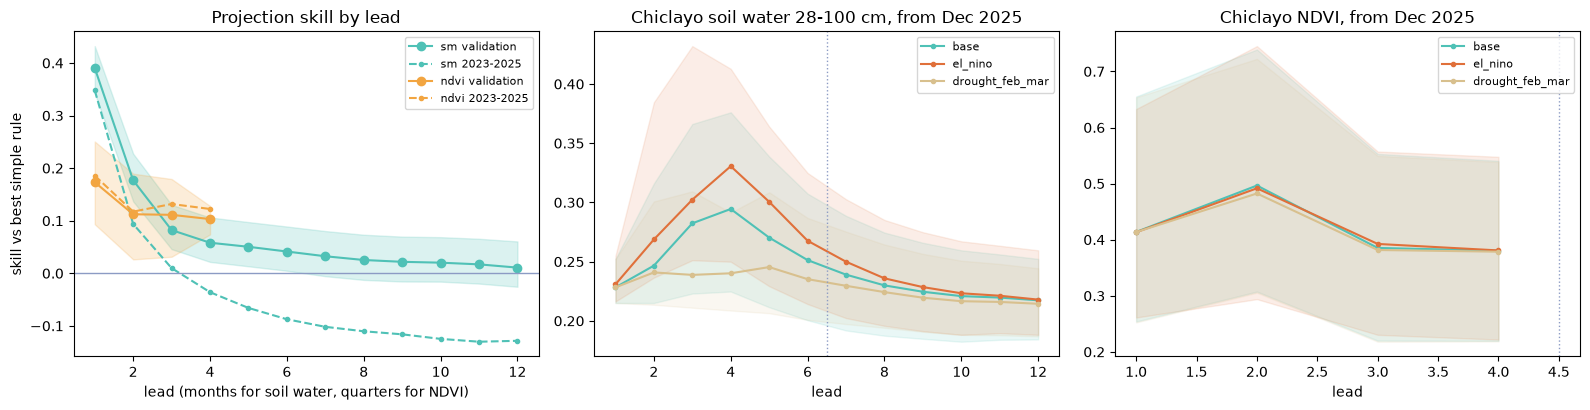

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for v, color in [("sm", "#4FC1B6"), ("ndvi", "#F2A541")]:
    t = SK[(v, "validation")]; ax[0].plot(t.lead, t.skill, marker="o", color=color, label=f"{v} validation")
    ax[0].fill_between(t.lead, t.skill_ci_low, t.skill_ci_high, color=color, alpha=0.2)
    t2 = SK[(v, "2023-2025")]; ax[0].plot(t2.lead, t2.skill, ls="--", marker=".", color=color, label=f"{v} 2023-2025")
ax[0].axhline(0, color="#8C9BC4", lw=1); ax[0].set_xlabel("lead (months for soil water, quarters for NDVI)"); ax[0].set_ylabel("skill vs best simple rule")
ax[0].set_title("Projection skill by lead"); ax[0].legend(fontsize=8)
ch = PROJ[(PROJ.province == "Chiclayo")]
for a, var, title in [(ax[1], "soil_water_28_100cm", "Chiclayo soil water 28-100 cm, from Dec 2025"), (ax[2], "ndvi", "Chiclayo NDVI, from Dec 2025")]:
    for scen, color in [("base", "#4FC1B6"), ("el_nino", "#E0703A"), ("drought_feb_mar", "#D8C08E")]:
        g = ch[(ch.variable == var) & (ch.scenario == scen)].groupby("lead", sort=True)[["median", "low_90", "high_90"]].mean()
        a.plot(g.index, g["median"], marker="o", ms=3, color=color, label=scen)
        a.fill_between(g.index, g.low_90, g.high_90, color=color, alpha=0.12)
    a.axvline(USEFUL["sm" if var.startswith("soil") else "ndvi"] + 0.5, color="#8C9BC4", ls=":", lw=1)
    a.set_title(title); a.set_xlabel("lead"); a.legend(fontsize=8)
plt.tight_layout(); fig.savefig(ART / "projections_overview.png", dpi=110); plt.show()

## 10. Save

In [12]:
PROJ.to_parquet(ART / "projection_2026_cells.parquet", index=False)
PROV.to_json(ART / "projection_2026_provinces.json", orient="records", indent=0)
pd.concat([t.assign(variable=v, period=p) for (v, p), t in SK.items()]).to_csv(ART / "hindcast_skill_by_lead.csv", index=False)
pd.concat([t.assign(variable=v) for v, t in COV.items()]).to_csv(ART / "hindcast_coverage_2023_2025.csv", index=False)
CHK.to_csv(ART / "scenario_sanity_checks.csv", index=False)
card = {"name": "Field Shift projections and scenarios", "status": "model level; no web or backend",
        "models": {"sm_root_monthly": SHA["sm_root_monthly"], "ndvi_quarterly": SHA["ndvi_quarterly"]},
        "method": "analog ensemble (Ensemble Streamflow Prediction, Day 1985): weather of each past year for the coming months, "
                  "run month by month from the observed state; band = 5-95% of members + per-lead correction (conformalized, Romano et al. 2019) "
                  "calibrated on Validation 2018-2022 hindcasts",
        "useful_lead": {"soil_water_months": USEFUL["sm"], "ndvi_quarters": USEFUL["ndvi"]},
        "correction_by_lead": CORR, "coverage_2023_2025": {v: t[t.lead == "all"].to_dict("records")[0] for v, t in COV.items()},
        "scenario_checks": summary, "scenarios": DESC, "start": "2025-12", "analog_years_output": [POOL[0], POOL[-1]],
        "beyond_useful_lead": "show as 'a typical year' (climatology), not as a projection",
        "not_for": ["crop yield, crop quality or exports (no yield data)", "a weather forecast (the coming rain is not predicted)",
                    "irrigated fields", "a measurement of one field (one 2 km cell)"],
        "versions": {"python": platform.python_version(), "xgboost": xgb.__version__, "pandas": pd.__version__}}
(ART / "projection_card.json").write_text(json.dumps(card, indent=1, default=str))
for f in sorted(ART.rglob("*")):
    if f.is_file(): print(f.relative_to(ML_DIR), f"{f.stat().st_size/1e6:.1f} MB")

artifacts/projections/hindcast_coverage_2023_2025.csv 0.0 MB
artifacts/projections/hindcast_skill_by_lead.csv 0.0 MB
artifacts/projections/projection_2026_cells.parquet 4.7 MB
artifacts/projections/projection_2026_provinces.json 0.1 MB
artifacts/projections/projection_card.json 0.0 MB
artifacts/projections/projections_overview.png 0.2 MB
artifacts/projections/scenario_sanity_checks.csv 0.0 MB
